# IPL Venue Analysis

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

matches = pd.read_csv("../data/cleaned/matches_clean.csv")
deliveries = pd.read_csv("../data/cleaned/deliveries_clean.csv")

## Business Question 1

Which IPL venues produce the highest scoring matches?

In [56]:
match_scores = (deliveries.groupby(['match_id', 'inning'])['total_runs'].sum().reset_index())

match_scores.head()

,match_id,inning,total_runs
0,335982,1,222
1,335982,2,82
2,335983,1,240
3,335983,2,207
4,335984,1,129


In [57]:
match_scores = match_scores.merge(
    matches[['id', 'venue']],
    left_on='match_id',
    right_on='id',
    how='left'
)

match_scores.head()

,match_id,inning,total_runs,id,venue
0,335982,1,222,335982,M Chinnaswamy Stadium
1,335982,2,82,335982,M Chinnaswamy Stadium
2,335983,1,240,335983,"Punjab Cricket Association IS Bindra Stadium, ..."
3,335983,2,207,335983,"Punjab Cricket Association IS Bindra Stadium, ..."
4,335984,1,129,335984,Arun Jaitley Stadium


In [58]:
venue_scores = (
    match_scores
    .groupby('venue')['total_runs']
    .mean()
    .sort_values(ascending=False)
)

venue_scores.head(20)

venue
Brabourne Stadium                                                        172.314815
Barsapara Cricket Stadium, Guwahati                                      169.833333
Himachal Pradesh Cricket Association Stadium                             169.692308
Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur       167.500000
Wankhede Stadium                                                         163.840336
Punjab Cricket Association IS Bindra Stadium, Mohali                     162.819672
Barabati Stadium                                                         162.714286
M Chinnaswamy Stadium                                                    162.497354
Green Park                                                               162.250000
Narendra Modi Stadium, Ahmedabad                                         161.040541
Arun Jaitley Stadium                                                     160.524862
Eden Gardens                                                          

In [59]:
venue_matches = (matches['venue'].value_counts())

valid_venues = (venue_matches[venue_matches >= 10].index)

In [60]:
venue_scores_filtered = (match_scores[match_scores['venue'].isin(valid_venues)]
    .groupby('venue')['total_runs']
    .mean()
    .sort_values(ascending=False)
)

venue_scores_filtered.head(20)

venue
Brabourne Stadium                                                        172.314815
Himachal Pradesh Cricket Association Stadium                             169.692308
Wankhede Stadium                                                         163.840336
Punjab Cricket Association IS Bindra Stadium, Mohali                     162.819672
M Chinnaswamy Stadium                                                    162.497354
Narendra Modi Stadium, Ahmedabad                                         161.040541
Arun Jaitley Stadium                                                     160.524862
Eden Gardens                                                             159.908602
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow    159.037037
Maharashtra Cricket Association Stadium                                  158.785714
Rajiv Gandhi International Stadium, Uppal                                155.525641
Sawai Mansingh Stadium                                                

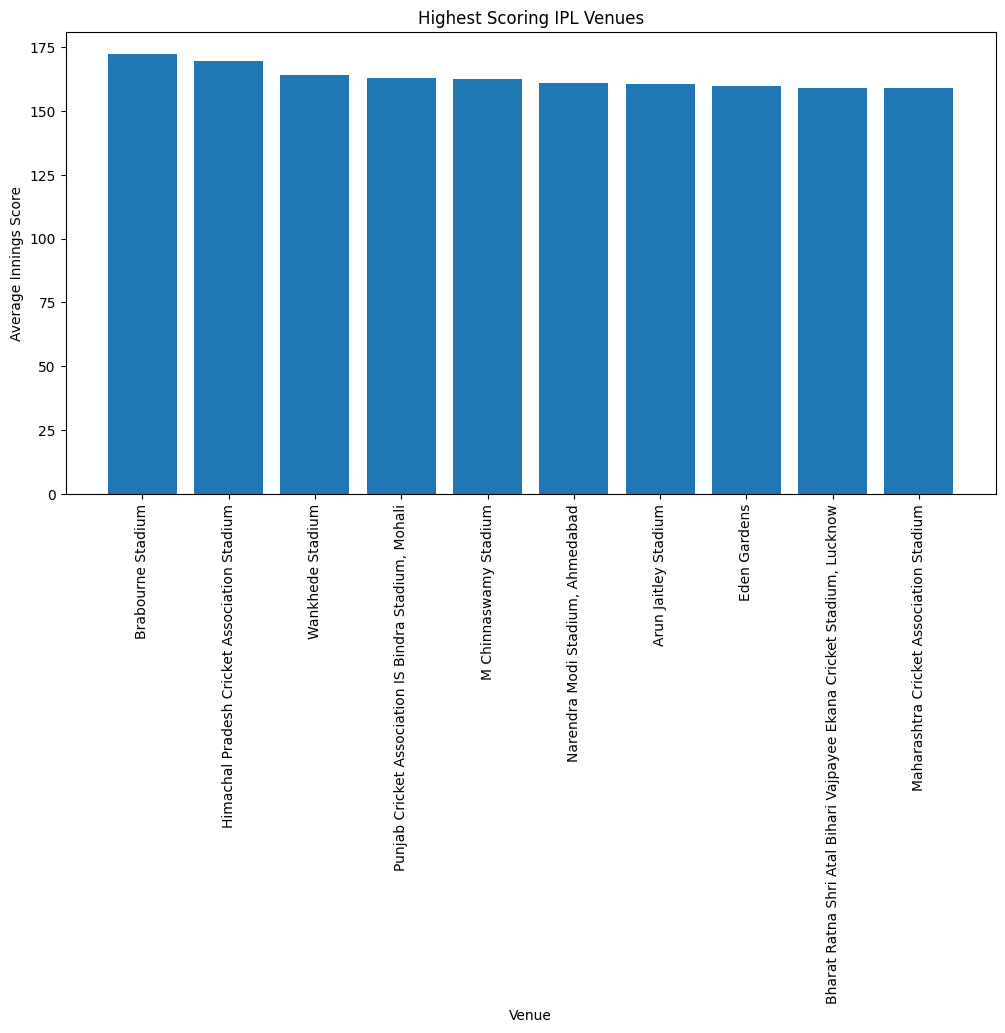

In [61]:
top_scoring = (venue_scores_filtered.head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_scoring.index,
    top_scoring.values
)

plt.title('Highest Scoring IPL Venues')

plt.xlabel('Venue')
plt.ylabel('Average Innings Score')

plt.xticks(rotation=90)

plt.show()

## Insight

Average innings score helps identify batting-friendly venues.

Higher averages generally indicate flatter pitches, shorter boundaries, or conditions that favor batters.

## Business Question 2

Which IPL venues produce the lowest scoring matches?

In [62]:
venue_scores_filtered.sort_values().head(20)

venue
Subrata Roy Sahara Stadium                                               141.500000
Dubai International Cricket Stadium                                      144.500000
Kingsmead                                                                145.100000
Sheikh Zayed Stadium                                                     145.282051
Saurashtra Cricket Association Stadium                                   151.500000
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium                      151.533333
SuperSport Park                                                          152.208333
Sharjah Cricket Stadium                                                  153.267857
MA Chidambaram Stadium, Chepauk                                          153.482759
Dr DY Patil Sports Academy, Mumbai                                       153.824324
Sawai Mansingh Stadium                                                   155.131579
Rajiv Gandhi International Stadium, Uppal                             

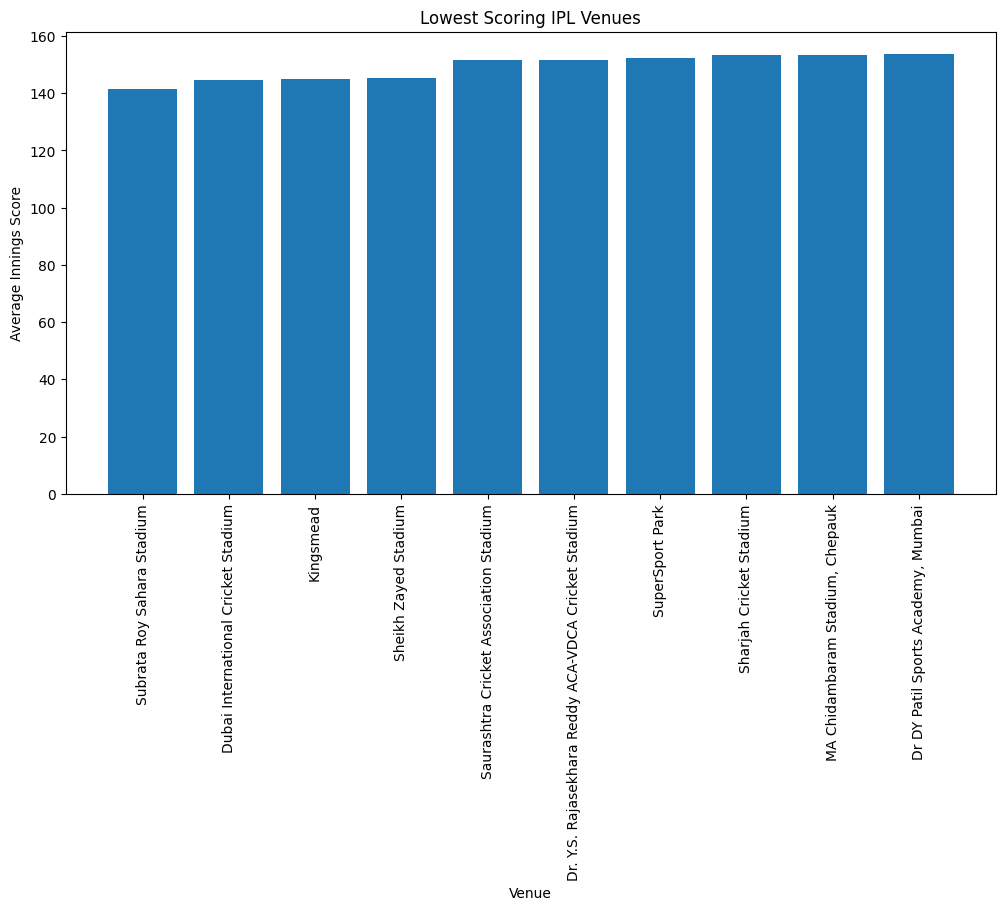

In [63]:
lowest_scoring = (venue_scores_filtered.sort_values().head(10))

plt.figure(figsize=(12,6))

plt.bar(
    lowest_scoring.index,
    lowest_scoring.values
)

plt.title('Lowest Scoring IPL Venues')

plt.xlabel('Venue')
plt.ylabel('Average Innings Score')

plt.xticks(rotation=90)

plt.show()

## Insight

Lower average scores generally indicate bowling-friendly conditions.

Factors may include slower pitches, larger boundaries, seam movement, spin assistance, or difficult batting conditions.

## Business Question 3

Which IPL venues are best for chasing targets?

In [64]:
first_innings = (deliveries[deliveries['inning'] == 2][['match_id', 'batting_team']].drop_duplicates())

In [65]:
first_innings = first_innings.merge(
    matches[['id', 'winner', 'venue']],
    left_on='match_id',
    right_on='id',
    how='left'
)

first_innings.head()

,match_id,batting_team,id,winner,venue
0,335982,Royal Challengers Bengaluru,335982,Kolkata Knight Riders,M Chinnaswamy Stadium
1,335983,Punjab Kings,335983,Chennai Super Kings,"Punjab Cricket Association IS Bindra Stadium, ..."
2,335984,Delhi Capitals,335984,Delhi Capitals,Arun Jaitley Stadium
3,335985,Royal Challengers Bengaluru,335985,Royal Challengers Bengaluru,Wankhede Stadium
4,335986,Kolkata Knight Riders,335986,Kolkata Knight Riders,Eden Gardens


In [66]:
successful_chases = first_innings[first_innings['batting_team'] == first_innings['winner']]
successful_chases.head()

,match_id,batting_team,id,winner,venue
2,335984,Delhi Capitals,335984,Delhi Capitals,Arun Jaitley Stadium
3,335985,Royal Challengers Bengaluru,335985,Royal Challengers Bengaluru,Wankhede Stadium
4,335986,Kolkata Knight Riders,335986,Kolkata Knight Riders,Eden Gardens
5,335987,Rajasthan Royals,335987,Rajasthan Royals,Sawai Mansingh Stadium
6,335988,Delhi Capitals,335988,Delhi Capitals,"Rajiv Gandhi International Stadium, Uppal"


In [67]:
venue_chasing = pd.DataFrame({
    'Matches': first_innings['venue'].value_counts(),
    'Successful_Chases': successful_chases['venue'].value_counts()
}).fillna(0)

In [68]:
venue_chasing['Chasing_%'] = (
    venue_chasing['Successful_Chases']
    /
    venue_chasing['Matches']
) * 100

In [69]:
venue_chasing = venue_chasing[venue_chasing['Matches'] >= 10]

In [70]:
venue_chasing.sort_values(by='Chasing_%', ascending=False).head(20)

,Matches,Successful_Chases,Chasing_%
venue,,,
Saurashtra Cricket Association Stadium,10,7,70.000000
SuperSport Park,12,8,66.666667
Sawai Mansingh Stadium,57,37,64.912281
Sharjah Cricket Stadium,28,18,64.285714
Eden Gardens,93,55,59.139785
"Narendra Modi Stadium, Ahmedabad",36,21,58.333333
Sheikh Zayed Stadium,37,21,56.756757
"Rajiv Gandhi International Stadium, Uppal",77,43,55.844156
"Punjab Cricket Association IS Bindra Stadium, Mohali",61,34,55.737705


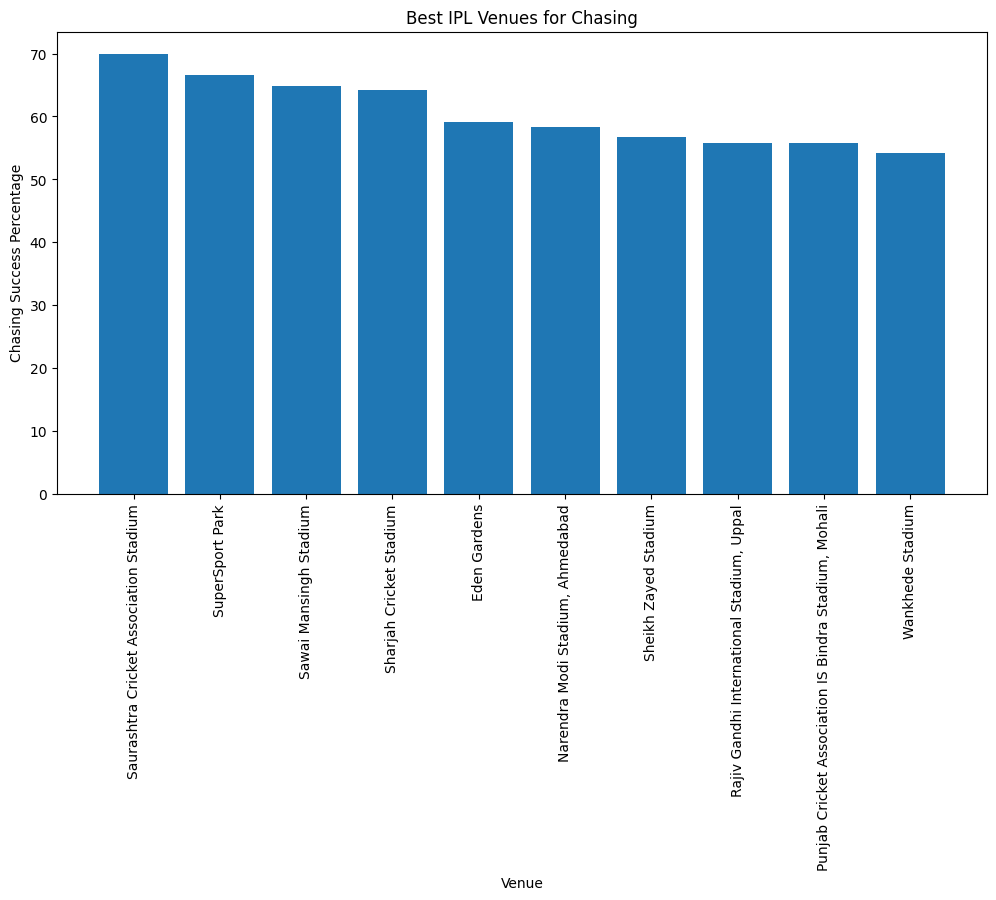

In [71]:
top_chasing = (venue_chasing.sort_values(by='Chasing_%', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_chasing.index,
    top_chasing['Chasing_%']
)

plt.title('Best IPL Venues for Chasing')

plt.xlabel('Venue')
plt.ylabel('Chasing Success Percentage')

plt.xticks(rotation=90)

plt.show()

## Business Question 4

Which IPL venues are best for defending totals?

In [72]:
first_innings = (deliveries[deliveries['inning'] == 1][['match_id', 'batting_team']].drop_duplicates())

In [73]:
first_innings = first_innings.merge(
    matches[['id', 'winner', 'venue']],
    left_on='match_id',
    right_on='id',
    how='left'
)

first_innings.head()

,match_id,batting_team,id,winner,venue
0,335982,Kolkata Knight Riders,335982,Kolkata Knight Riders,M Chinnaswamy Stadium
1,335983,Chennai Super Kings,335983,Chennai Super Kings,"Punjab Cricket Association IS Bindra Stadium, ..."
2,335984,Rajasthan Royals,335984,Delhi Capitals,Arun Jaitley Stadium
3,335985,Mumbai Indians,335985,Royal Challengers Bengaluru,Wankhede Stadium
4,335986,Deccan Chargers,335986,Kolkata Knight Riders,Eden Gardens


In [74]:
successful_defends = first_innings[
    first_innings['batting_team']
    ==
    first_innings['winner']
]

In [75]:
venue_defending = pd.DataFrame({
    'Matches': first_innings['venue'].value_counts(),
    'Successful_Defends': successful_defends['venue'].value_counts()
}).fillna(0)

In [76]:
venue_defending['Defending_%'] = (
    venue_defending['Successful_Defends']
    /
    venue_defending['Matches']
) * 100

In [77]:
venue_defending = venue_defending[venue_defending['Matches'] >= 10]

In [78]:
venue_defending.sort_values(by='Defending_%',ascending=False).head(20)

,Matches,Successful_Defends,Defending_%
venue,,,
Subrata Roy Sahara Stadium,16,10.0,62.500000
Himachal Pradesh Cricket Association Stadium,13,8.0,61.538462
"MA Chidambaram Stadium, Chepauk",85,49.0,57.647059
Kingsmead,15,8.0,53.333333
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium,15,8.0,53.333333
Brabourne Stadium,27,14.0,51.851852
Maharashtra Cricket Association Stadium,35,18.0,51.428571
Dubai International Cricket Stadium,46,23.0,50.000000
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",14,7.0,50.000000


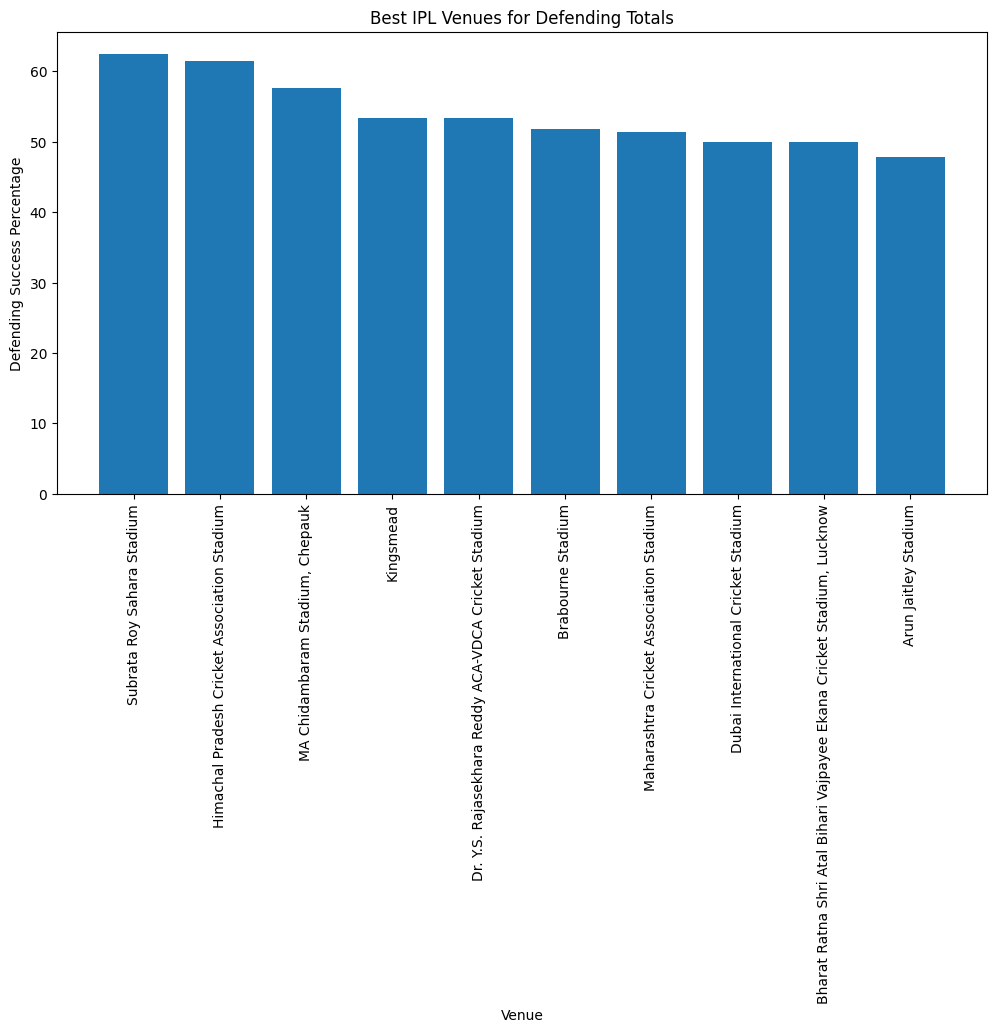

In [79]:
top_defending = (venue_defending.sort_values(by='Defending_%', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_defending.index,
    top_defending['Defending_%']
)

plt.title('Best IPL Venues for Defending Totals')

plt.xlabel('Venue')
plt.ylabel('Defending Success Percentage')

plt.xticks(rotation=90)

plt.show()

## Insight

This analysis measures how often teams batting first successfully defend their totals.

A higher defending percentage suggests that scoreboard pressure and venue conditions make chasing more difficult.

## Business Question 5

Which IPL venues have the strongest impact on match outcomes?

In [80]:
venue_impact = pd.DataFrame({
    'Average_Score': venue_scores_filtered,
    'Chasing_%': venue_chasing['Chasing_%'],
    'Defending_%': venue_defending['Defending_%']
})

venue_impact = venue_impact.fillna(0)

venue_impact.head()

,Average_Score,Chasing_%,Defending_%
venue,,,
Arun Jaitley Stadium,160.524862,51.685393,47.777778
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",159.037037,46.153846,50.000000
Brabourne Stadium,172.314815,48.148148,51.851852
"Dr DY Patil Sports Academy, Mumbai",153.824324,54.054054,45.945946
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium,151.533333,46.666667,53.333333


In [81]:
for col in venue_impact.columns:

    venue_impact[col + '_Score'] = (
        (
            venue_impact[col]
            -
            venue_impact[col].min()
        )
        /
        (
            venue_impact[col].max()
            -
            venue_impact[col].min()
        )
    ) * 100

In [82]:
venue_impact['Venue_Impact_Score'] = (
      venue_impact['Average_Score_Score'] * 0.40
    + venue_impact['Chasing_%_Score'] * 0.30
    + venue_impact['Defending_%_Score'] * 0.30
)

In [83]:
venue_impact.sort_values(by='Venue_Impact_Score', ascending=False).head(20)

,Average_Score,Chasing_%,Defending_%,Average_Score_Score,Chasing_%_Score,Defending_%_Score,Venue_Impact_Score
venue,,,,,,,
Brabourne Stadium,172.314815,48.148148,51.851852,100.000000,32.763533,67.236467,70.000000
Himachal Pradesh Cricket Association Stadium,169.692308,38.461538,61.538462,91.489460,2.958580,97.041420,66.595784
Wankhede Stadium,163.840336,54.237288,45.762712,72.498687,51.499348,48.500652,58.999475
"Punjab Cricket Association IS Bindra Stadium, Mohali",162.819672,55.737705,44.262295,69.186436,56.116015,43.883985,57.674574
"Narendra Modi Stadium, Ahmedabad",161.040541,58.333333,41.666667,63.412812,64.102564,35.897436,55.365125
M Chinnaswamy Stadium,162.497354,53.763441,43.617021,68.140453,50.041356,41.898527,54.838146
Arun Jaitley Stadium,160.524862,51.685393,47.777778,61.739335,43.647364,54.700855,54.200200
Eden Gardens,159.908602,59.139785,40.860215,59.739454,66.583954,33.416046,53.895782
Maharashtra Cricket Association Stadium,158.785714,48.571429,51.428571,56.095467,34.065934,65.934066,52.438187


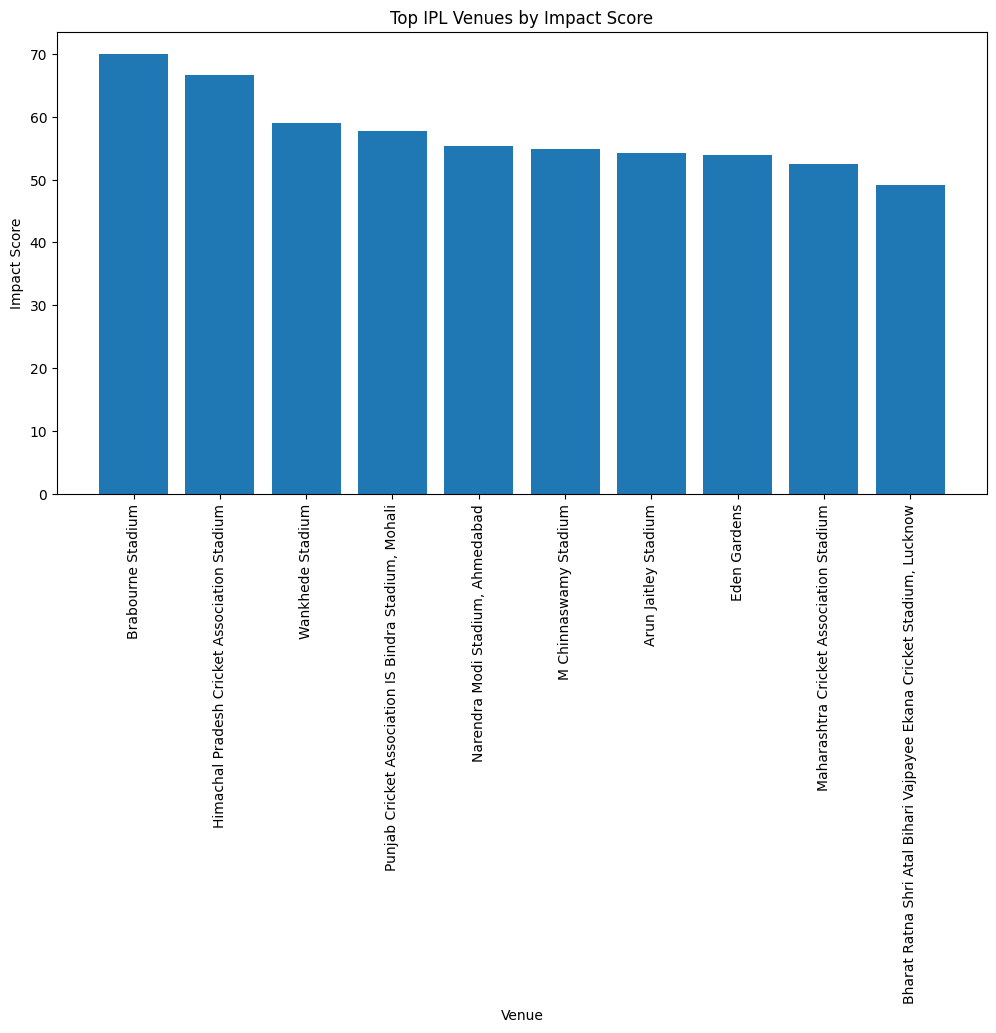

In [84]:
top_venues = (venue_impact.sort_values(by='Venue_Impact_Score', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_venues.index,
    top_venues['Venue_Impact_Score']
)

plt.title('Top IPL Venues by Impact Score')

plt.xlabel('Venue')
plt.ylabel('Impact Score')

plt.xticks(rotation=90)

plt.show()

## Insight

The Venue Impact Score combines scoring environment and match outcome tendencies into a single metric.

It helps identify venues that consistently influence how matches are played and won.